# Assignment 1 — Do personas annotate like people, and does context change them?

**Student:** Ioannis Petridis (f3352601)
**Course:** Practical Data Science, MSc in Data Science, AUEB
**GitHub repository:** https://github.com/PetridhsG/practical-data-science-assignment-1
**Seed:** `542685`

## Project description

Toxicity is subjective: two careful readers can rate the same comment differently. In this notebook I rate
20 online comments for toxicity myself, and then ask a small LLM to rate the same comments while playing
annotators with different identities (personas), once with the surrounding conversation as context and once
without it. Comparing the ratings tells me whether any persona annotates like me, and whether context changes
how the personas judge toxicity.

## Setup

**Tools.** The conversations (part C) and the persona annotators (parts D and E) are run with
[SynDisco](https://pypi.org/project/syndisco/), a library for synthetic discussions and annotation with LLMs.
SynDisco loads the model through Hugging Face `transformers`, which it installs together with its other
dependencies. The model is a 4-bit quantised instruction-tuned model, so the notebook runs on a Google Colab
**T4 GPU**.

Only `syndisco` has to be installed: `torch`, `pandas`, `numpy`, `matplotlib` and `IPython` are preinstalled on
Colab, and the rest are part of the Python standard library.

In [1]:
%pip install -q syndisco

Note: you may need to restart the kernel to use updated packages.


In [2]:
import html                                 # to escape the texts inside the HTML output
import itertools                            # to build every combination of the persona grid
import json                                 # to save and load the conversations
import random                               # to choose random participants
import re                                   # to find the rating and evidence in the model's answer
from urllib.error import HTTPError          # raised when a saved file is not on GitHub yet
from urllib.request import urlopen          # to download the saved files from GitHub
from pathlib import Path                    # to check if the saved files already exist

import matplotlib.pyplot as plt             # for the plots
import numpy as np                          # SynDisco's turn manager expects a NumPy random generator
import pandas as pd                         # for the tables
import syndisco                             # conversations and annotators
import torch                                # the library that runs the model
from IPython.display import HTML, display   # to show tables and conversations in scrollable boxes


SEED = 542685                    # the seed of prepare_items.py, reused for every random choice
random.seed(SEED)
torch.manual_seed(SEED)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: none (Runtime > Change runtime type > T4 GPU)


### Helper functions for the output

Small functions used throughout the notebook to make the results easy to read:

- `show_table(df)`: shows a table in full in a scrollable box, with the texts wrapped and the labels coloured
  (green civil, red toxic). Used for the items and my ratings (part B).
- `clean(text)`: removes the double quotes the model puts around every reply (part C).
- `as_text(conversation)`: turns a conversation into plain `name: text` lines; this is the form the annotators
  read as context in part D.
- `as_html(item_id, conversation)` and `show_conversations(conversations)`: show the 20 conversations in a
  scrollable box, with the item as a quote and the speaker of each reply in bold (part C).

In [3]:
def show_table(df, height=450):
    """Show a table in full in a scrollable box: no index, texts left-aligned and wrapped, labels coloured (green civil, red toxic), missing values blank."""
    styler = (
        df.style.hide(axis="index")
        .format(na_rep="")                               # missing values as blanks
        .set_properties(**{"text-align": "left", "vertical-align": "top"})
        .set_properties(subset=["text"], **{"white-space": "normal", "min-width": "420px"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    )
    if "prompt" in df.columns:                           # the prompt is long: smaller font, wrapped
        styler = styler.set_properties(subset=["prompt"], **{"white-space": "normal", "min-width": "480px",
                                                             "font-size": "0.8em"})
    if "label" in df.columns:
        colors = {"civil": "rgba(46, 160, 67, 0.25)", "toxic": "rgba(218, 54, 51, 0.25)"}
        styler = styler.map(lambda v: f"background-color: {colors.get(v, '')}", subset=["label"])
    display(HTML(f"<div style='max-height:{height}px;overflow-y:auto'>{styler.to_html()}</div>"))


def clean(text):
    """Llama wraps every reply in double quotes: strip them (the saved file keeps the raw replies)."""
    return text.strip().strip('"').strip()


def as_text(conversation):
    """One line per comment: 'name: text' (the form the annotators read in part D)."""
    return "\n".join(f"{c['name']}: {clean(c['text'])}" for c in conversation)


def as_html(item_id, conversation):
    """One conversation: the item as a quote, then one line per reply with the speaker in bold."""
    opening, replies = conversation[0], conversation[1:]
    rows = "".join(
        f"<li style='margin:4px 0'><b>{html.escape(c['name'])}</b>: {html.escape(clean(c['text']))}</li>"
        for c in replies
    )
    return (
        f"<h4 style='margin:14px 0 6px'>Item {item_id}</h4>"
        f"<blockquote style='margin:0 0 6px;padding:6px 10px;border-left:4px solid #888'>"
        f"<b>{html.escape(opening['name'])}</b> (the item): {html.escape(clean(opening['text']))}</blockquote>"
        f"<ul style='margin:0;padding-left:20px'>{rows}</ul>"
    )


def show_conversations(conversations, height=520):
    """All the conversations in one scrollable box, about 2-3 at a time."""
    body = "".join(as_html(item_id, conversation) for item_id, conversation in conversations.items())
    display(HTML(f"<div style='max-height:{height}px;overflow-y:auto;padding:0 12px;border:1px solid #888;"
                 f"border-radius:6px;line-height:1.45'>{body}</div>"))

> ### IMPORTANT NOTE REGARDING THE MODEL AND THE GENERATED DATA
>
> Generating the conversations (C) and the annotations (D and E) needs a GPU
> and takes time, so I generated them once, saved them under `data/` and pushed them to the repository. When
> the notebook runs, it loads them from `data/` (or from GitHub) instead of generating them again. This is why
> the outputs of C, D and E say *"Loaded ..."* instead of showing the model run. To generate
> everything again from the start, set `REGENERATE = True` (C) or `REGENERATE_ANN = True` (D and E). Because the
> seed is fixed and the model decodes greedily, a new run gives the same results. The model itself is loaded
> only when a GPU is found. Without a GPU it is skipped and the saved files are used, and if those cannot be
> found either, the notebook stops with an error saying that a GPU is needed to generate them. I did this because I ran out
> of free GPU time on Google Colab: I used a second account to generate the data once, and then worked on the
> rest of the assignment (F and the conclusions) locally, without a GPU.
>
> The screenshots below are from the actual runs on a Colab T4: loading the model (about 2 minutes), and
> the annotations of D (about 18 minutes) and E (about 14 minutes):
>
> 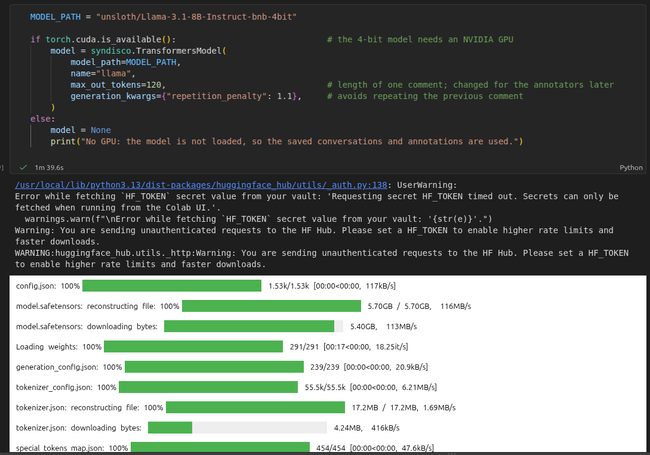
>
> 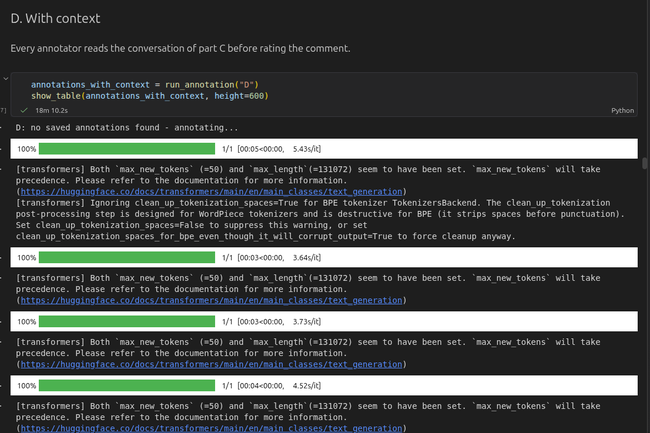
>
> 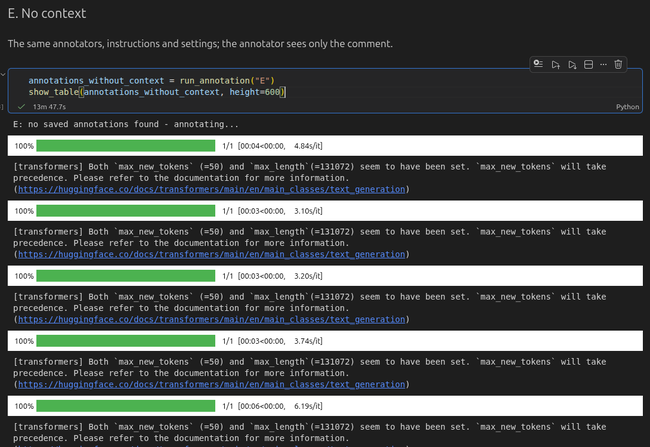

## A. My own annotation

I drew my sample with `python prepare_items.py --seed 542685`: 20 comments from news-site discussions,
a balanced mix of civil and toxic texts taken from a pool of 250. The script wrote `items.csv` and
`annotate.html`, the page I used for rating.

I rated each item on a 1-5 scale of how uncivil or hostile its language is, judging the tone and not the
topic (1-2 = civil, 3-5 = toxic). For ratings 3-5 I selected the words that make the text toxic as evidence.
I rated alone, before seeing any model output, and never changed a rating. The result is
`items_rated.csv` (id, text, rating, label, evidence).

Both `items.csv` and `items_rated.csv` are uploaded to the
[`data/` folder of the GitHub repository](https://github.com/PetridhsG/practical-data-science-assignment-1/tree/main/data),
and the notebook reads them directly from there, so no local copy is needed.

## B. Exploratory data analysis

Both files are read directly from the `data/` folder of the GitHub repository, so the notebook needs no
local files.

In [4]:
DATA_URL = "https://raw.githubusercontent.com/PetridhsG/practical-data-science-assignment-1/main/data/"

items = pd.read_csv(DATA_URL + "items.csv")              # the sample from prepare_items.py
items_rated = pd.read_csv(DATA_URL + "items_rated.csv")        # my ratings from annotate.html
print("items:", items.shape, " rated:", items_rated.shape)

items: (20, 5)  rated: (20, 5)


The unrated sample, in full:

In [5]:
show_table(items.fillna(""))   # the rating, label and evidence columns are still empty here

id,text,rating,label,evidence
1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,,,
2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,,,
3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,,,
4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,,,
5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",,,
6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",,,
7,Great call! An adulterer married to a serial monogamist and adulterer.,,,
8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",,,
9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",,,
10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",,,


My ratings, in full:

In [6]:
show_table(items_rated)

id,text,rating,label,evidence
1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,4,toxic,ignorant fool
2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,2,civil,not needed
3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,2,civil,not needed
4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,1,civil,not needed
5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",2,civil,not needed
6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",4,toxic,pathetic shrieking asshole || have his ass kicked
7,Great call! An adulterer married to a serial monogamist and adulterer.,2,civil,not needed
8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",2,civil,not needed
9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",3,toxic,shut up everybody
10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",2,civil,not needed


How I used the scale: counts per rating and per label, and a summary of the ratings.

In [7]:
counts = items_rated.rating.value_counts().sort_index()
labels = items_rated.label.value_counts().sort_index()

print(pd.DataFrame({"items": counts, "share": (counts / len(items_rated)).round(2)}).rename_axis("rating"), "\n")
print(pd.DataFrame({"items": labels, "share": (labels / len(items_rated)).round(2)}).rename_axis("label"), "\n")

        items  share
rating              
1           3   0.15
2           9   0.45
3           3   0.15
4           4   0.20
5           1   0.05 

       items  share
label              
civil     12    0.6
toxic      8    0.4 



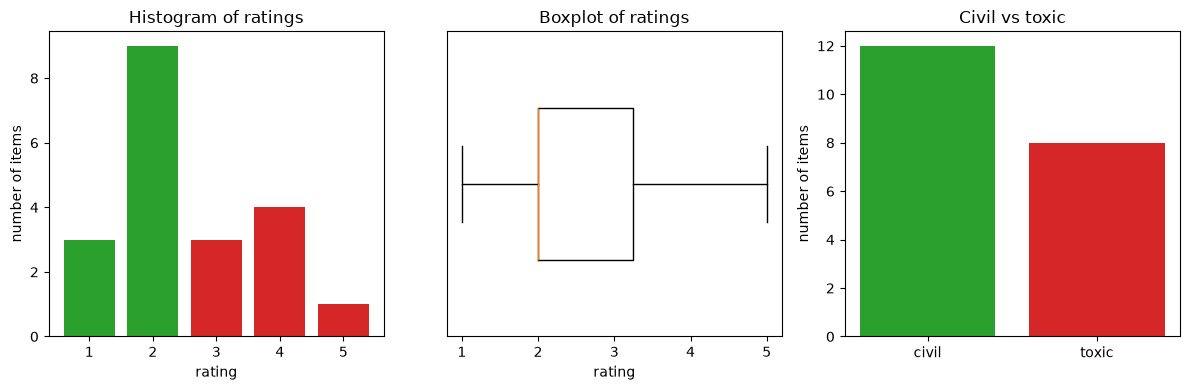

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
colors = ["tab:green"] * 2 + ["tab:red"] * 3                              # civil 1-2, toxic 3-5

axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set(title="Histogram of ratings", xlabel="rating", ylabel="number of items", xticks=range(1, 6))

axes[1].boxplot(items_rated.rating, orientation="horizontal", widths=0.5)
axes[1].set(title="Boxplot of ratings", xlabel="rating", yticks=[], xticks=range(1, 6))

axes[2].bar(labels.index, labels.values, color=["tab:green", "tab:red"])
axes[2].set(title="Civil vs toxic", ylabel="number of items")

plt.tight_layout()
plt.show()

I used the whole scale, from 1 to 5, but I lean towards civil: 12 of the 20 items are civil (9 of them
rated 2, the most common rating) and 8 are toxic, with only one item rated 5. The boxplot shows the same
lean, with the median at 2 and the middle half of the ratings between 2 and 3.25.

## C. Generate the conversations

Now we generate one short conversation for each of the 20 comments with SynDisco. First we create a pool of
participants with different personas (identities and ways of talking). Then, for each comment, a few of them
are picked at random and discuss it, with the comment as the opening post. These conversations will be used
later as context for the annotators in part D.

### The model

We use `unsloth/Llama-3.1-8B-Instruct-bnb-4bit`, an 8B instruction-tuned model quantised to 4 bits so it fits
on the T4 (about 6 GB). It is larger than the default 3B model, so it should follow the instructions better. The same model is used for all three parts.
The model is loaded only when a GPU is available. Without one (for example when running locally), it is skipped
and the saved conversations and annotations are used instead.


In [9]:
MODEL_PATH = "unsloth/Llama-3.1-8B-Instruct-bnb-4bit"

if torch.cuda.is_available():                              # the 4-bit model needs an NVIDIA GPU
    model = syndisco.TransformersModel(
        model_path=MODEL_PATH,
        name="llama",
        max_out_tokens=120,                                # length of one comment; changed for the annotators later
        generation_kwargs={"repetition_penalty": 1.1},     # avoids repeating the previous comment
    )
else:
    model = None
    print("No GPU: the model is not loaded, so the saved conversations and annotations are used.")


No GPU: the model is not loaded, so the saved conversations and annotations are used.


### The participants

These personas only take part in the conversations; they are not the annotators of parts D and E. Each one has
a username, gender, political orientation and age, mixed so that the conversations are varied. I also added
two dimensions, **education** and **religion**, to see how these two can affect the outcome. For every
comment, 3 of the 8 are picked at random.

In [10]:
# the pool of conversation participants (not the annotator grid of parts D and E)
PERSONAS = [
    {"username": "Maria_K",   "gender": "woman", "politics": "left",   "age": 38, "education": "master's degree", "religion": "Christian"},
    {"username": "Nikos_88",  "gender": "man",   "politics": "right",  "age": 36, "education": "high school", "religion": "Christian"},
    {"username": "Eleni_P",   "gender": "woman", "politics": "left",   "age": 24, "education": "bachelor's degree", "religion": "atheist"},
    {"username": "Tom_77",    "gender": "man",   "politics": "right",  "age": 47, "education": "high school", "religion": "Christian"},
    {"username": "Sofia_R",   "gender": "woman", "politics": "centre", "age": 29, "education": "master's degree", "religion": "agnostic"},
    {"username": "George_V",  "gender": "man",   "politics": "left",   "age": 63, "education": "PhD", "religion": "atheist"},
    {"username": "Aisha_M",   "gender": "woman", "politics": "right",  "age": 55, "education": "bachelor's degree", "religion": "Muslim"},
    {"username": "Kostas_21", "gender": "man",   "politics": "centre", "age": 21, "education": "high school", "religion": "Christian"},
]

# the same context and instructions for every participant
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the previous comments, in the first person, "
    "in your own voice. React to what was said and do not repeat what others already wrote. "
    "Do not explain, do not refuse, and do not mention that you are an AI."
)
N_PARTICIPANTS = 3      # participants per conversation
CONV_LEN = 4            # number of replies the model writes

**Why these settings.** A pool of **8 personas** gives 56 possible groups of 3, so the 20 conversations have
different participants without the pool getting large. **3 participants** with **4 replies** (`CONV_LEN`) means
usually all three speak (in 6 of the 20 conversations only two of them do) and someone gets to reply back, so it reads like a discussion and not a list of
opinions. Keeping the conversation short keeps it on the item, avoids drift and repetition, and keeps the
context the annotators read in part D small.

### Generating the conversations

For each comment, 3 participants are picked at random from the pool and SynDisco runs the discussion, with the
comment as the opening post by `OriginalPoster`. Every participant sees the whole conversation so far (the
opening comment plus up to 4 earlier replies). Both random choices are fixed by the seed: which participants
take part (`random.Random(SEED)`) and who speaks next (a NumPy generator seeded with `SEED + id`; SynDisco's
turn manager is otherwise unseeded). The conversations are saved to `data/conversations.json` and pushed to the GitHub
repository; when the file exists (locally or on GitHub) it is loaded instead of generating the conversations again.

In [11]:
REGENERATE = False                               # True: ignore the saved file and generate the conversations again
CONV_FILE = Path("data/conversations.json")      # local copy, pushed to GitHub after the first run

def load_conversations():
    """The saved conversations and where they came from: the local file, GitHub, or (None, None)."""
    if CONV_FILE.exists():
        return json.loads(CONV_FILE.read_text()), f"local file {CONV_FILE}"
    try:
        with urlopen(DATA_URL + "conversations.json") as f:
            return json.loads(f.read()), "GitHub"
    except HTTPError:                      # not on GitHub yet
        return None, None

saved, source = (None, None) if REGENERATE else load_conversations()
if saved is not None:
    conversations = {int(k): v for k, v in saved.items()}  # JSON keys are strings
    print(f"Loaded {len(conversations)} conversations from {source}, no generation needed.")
else:
    print("REGENERATE is on" if REGENERATE else "No saved conversations found", "- generating all of them with the model...")
    if model is None:
        raise RuntimeError(f"No GPU, so the conversations cannot be generated. Run on a GPU or add {CONV_FILE}.")
    rng = random.Random(SEED)                           # who takes part in each conversation
    conversations = {}                                 
    for item_id, text in zip(items_rated.id, items_rated.text):
        users = [
            syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
            for p in rng.sample(PERSONAS, N_PARTICIPANTS)
        ]
        discussion = syndisco.Discussion(
            next_turn_manager=syndisco.RandomTurnManager(users, random_state=np.random.default_rng(SEED + item_id)),
            users=users,
            conv_len=CONV_LEN,
            seed_opinions=[text],                       # the comment opens the thread...
            seed_opinion_usernames=["OriginalPoster"],  # ...as if written by this user
        )
        discussion.begin(verbose=False)
        conversations[item_id] = discussion.get_logs().to_list()
    CONV_FILE.parent.mkdir(exist_ok=True)
    CONV_FILE.write_text(json.dumps(conversations, indent=2, ensure_ascii=False))
    print(f"Generated {len(conversations)} conversations and saved them to {CONV_FILE}.")


Loaded 20 conversations from local file data/conversations.json, no generation needed.


All 20 conversations. The model wrapped every reply in double quotes; they are removed when the conversations
are printed and given to the annotators, while `data/conversations.json` keeps the raw replies.

In [12]:
show_conversations(conversations)

## D,E. Model annotations

Now the model plays annotators with different personas (the personas grid) and rates each of my 20 comments,
like I did: a rating from 1 to 5 and, for ratings 3-5, the toxic words of the comment as evidence. Every
annotator rates every comment twice: in **D (with context)** it first reads the conversation generated for the
comment in part C, then rates the comment itself; in **E (no context)** it sees only the comment. Everything
else (model, settings, instructions, persona) is the same in both conditions. A baseline annotator with no
persona rates the comments too, to see whether the personas change anything.

### The annotator grid

The example grid of the assignment is gender {woman, man} × politics {left, right} × age {under 30, over 50}.
I **changed** it: I kept gender and politics and replaced age with **religion** {religious, non-religious}, a
dimension the example does not have and one I also gave to the conversation participants. I want to see how it
affects the ratings: religion can change how offensive a comment about values, morality or a group feels.

**Why it is small.** Every cell of the grid annotates all 20 items twice (with and without context), so each
extra dimension doubles the work. With two values per dimension, 3 dimensions give 2 × 2 × 2 = **8 personas**,
plus the **baseline** (no persona): 9 annotators × 20 items × 2 conditions = **360 answers**, which keeps the
run short on a free T4. Two values per dimension also keep each comparison simple: for every dimension, 4
personas are on each side, so its effect can be read directly. Adding education as well would double this to
16 personas and 680 answers.

Each persona contains only who the annotator is, never how to rate. Its label (e.g. `woman, left, religious`)
is used only in the tables; it is not part of the prompt.

In [13]:
GRID = {
    "gender":    ["woman", "man"],
    "politics":  ["left", "right"],
    "religion":  ["religious", "non-religious"],
}

# every combination of the grid is one persona; the baseline has no persona at all
ANNOTATORS = {"baseline": {}}
for values in itertools.product(*GRID.values()):
    persona = dict(zip(GRID, values))
    ANNOTATORS[", ".join(values)] = persona          # the label is only for the tables

print(len(ANNOTATORS) - 1, "personas + baseline")
pd.DataFrame([{"annotator": label, **persona} for label, persona in ANNOTATORS.items()]).fillna("-")

8 personas + baseline


,annotator,gender,politics,religion
0,baseline,-,-,-
1,"woman, left, religious",woman,left,religious
2,"woman, left, non-religious",woman,left,non-religious
3,"woman, right, religious",woman,right,religious
4,"woman, right, non-religious",woman,right,non-religious
5,"man, left, religious",man,left,religious
6,"man, left, non-religious",man,left,non-religious
7,"man, right, religious",man,right,religious
8,"man, right, non-religious",man,right,non-religious


### Instructions and context

The instructions repeat the scale of `annotate.html` (shortened) and ask for a fixed format, `rating | evidence`,
so the answers can be parsed. The conversation goes in the **context**, not in the log: SynDisco labels every entry
of the log, so the log holds only the comment. The answer is short, so the output limit is lowered to 50 tokens.

In [14]:
# the task: the same for every annotator, in both conditions (the guidelines of annotate.html, shortened)
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. "
    "Judge the tone, not the topic.\n"
    "1 = fully civil: respectful, even if it disagrees strongly.\n"
    "2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n"
    "3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n"
    "4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n"
    "5 = very toxic: slurs, threats, harassment, hate.\n"
    "Answer with one line in exactly this format: rating | evidence\n"
    "For a rating of 3, 4 or 5, the evidence is the words of the comment that make it toxic, copied exactly "
    "from the comment (separate several passages with ' || '). For a rating of 1 or 2, write: rating | none\n"
    "Write nothing else."
)

# the context: the same sentence in both conditions; only D adds the conversation
BASE_CONTEXT = "You are annotating comments from an online discussion on a news website."


def make_context(conversation=None):
    """The annotator's context: E (no conversation) gets only the base sentence, D also gets the conversation."""
    if conversation is None:
        return BASE_CONTEXT
    return (BASE_CONTEXT + " Before you rate, read the conversation that people had about the comment:\n"
            + as_text(conversation))


if model is not None:
    model.max_out_tokens = 50     # a rating and a few quoted words (the conversation replies needed 120)

### Annotating

`annotate()` builds one annotator (persona, context, instructions) and runs SynDisco's annotation job on a log
that holds only the comment. It returns the raw answer and the prompt SynDisco saved with it. `parse()` reads
`rating | evidence` from the answer, removing the quotes and the `evidence:` the model often writes before
the quoted words (this only reads the format; the words themselves are not changed), and checks it: an answer is **invalid** if it has no rating from 1 to 5, or
if it rates 3-5 and its evidence is missing or not found in the comment (compared ignoring case). Invalid answers
are kept and counted, never fixed.

In [15]:
def annotate(text, persona, label, conversation=None):
    """One answer of one annotator for one comment. D passes the conversation, E does not."""
    annotator = syndisco.Actor(
        model=model, persona=persona, context=make_context(conversation),
        instructions=RATING_INSTRUCTIONS, is_annotator=True, name=label,   # name is only a label for the logs
    )

    logs = syndisco.Logs()
    logs.append("comment", text)                          # the log holds only the comment: that is what gets rated
    
    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    
    entry = job.get_logs()[0]
    return entry["text"], entry["prompt"]                 # the raw answer and the prompt SynDisco saved


def clean_passage(e):
    """One evidence passage without the quotes and the 'evidence:' the model sometimes writes before it."""
    e = e.strip().strip('"\'').strip()
    return re.sub(r"^evidence\s*:\s*", "", e, flags=re.I).strip().strip('"\'').strip()


def parse(answer, text):
    """Read 'rating | evidence' from an answer and check it. Returns rating, label, evidence, valid, problem."""
    found = re.search(r"([1-5])\s*\|(.*)", answer) or re.match(r"\s*\W*([1-5])\b()", answer)
    if not found:
        return None, None, None, False, "no rating 1-5"
    rating = int(found.group(1))
    if rating <= 2:
        return rating, "civil", "not needed", True, ""
    passages = [clean_passage(e) for e in found.group(2).split("\n")[0].split("||")]
    passages = [e for e in passages if e and e.lower() != "none"]
    if not passages:
        return rating, "toxic", "", False, "no evidence"
    missing = [e for e in passages if e.lower() not in text.lower()]
    if missing:
        return rating, "toxic", " || ".join(passages), False, "evidence not in item"
    return rating, "toxic", " || ".join(passages), True, ""

Now all annotators on all items, in both conditions (9 annotators × 20 items × 2 = 360 answers). The
annotations (annotator, id, text, rating, label, evidence, prompt) are saved in two files, `data/annotations_with_context.csv` (D) and
`data/annotations_no_context.csv` (E), and pushed to GitHub. If a file exists (locally or on GitHub) it is loaded
instead of annotating again. `REGENERATE_ANN = True` annotates everything
again from the start, ignoring any saved file.

In [16]:
REGENERATE_ANN = False                         # True: ignore the saved files and annotate everything again
ANN_FILES = {                                  # one file per condition, pushed to GitHub after the run
    "D": Path("data/annotations_with_context.csv"),
    "E": Path("data/annotations_no_context.csv"),
}
ANN_COLUMNS = ["annotator", "id", "text", "rating", "label", "evidence", "prompt"]


def parse_answers(raw):
    """Add rating, label and evidence read from every raw answer; nothing is fixed (invalid answers are counted below)."""
    parsed = raw.apply(lambda r: parse(r.answer, r.text)[:3], axis=1, result_type="expand")
    raw[["rating", "label", "evidence"]] = parsed
    raw["rating"] = raw.rating.astype("Int64")          # integer ratings, with <NA> when there is none
    return raw[ANN_COLUMNS]


def load_annotations(file):
    """The saved annotations of one condition and where they came from: the local file, GitHub, or (None, None)."""
    if file.exists():
        df, source = pd.read_csv(file), f"local file {file}"
    else:
        try:
            df, source = pd.read_csv(DATA_URL + file.name), "GitHub"
        except HTTPError:            # not on GitHub yet
            return None, None
    df["rating"] = df["rating"].astype("Int64")   # a missing rating is read back as a float NaN
    return df, source


def run_annotation(cond):
    """The final annotations of one condition (D with context, E without): the saved file if there is one,
    otherwise every annotator rates every item, the answers are parsed and the result is saved."""
    file = ANN_FILES[cond]
    saved, source = (None, None) if REGENERATE_ANN else load_annotations(file)
    if saved is not None:
        print(f"{cond}: loaded {len(saved)} annotations from {source}.")
        return saved

    print(f"{cond}:", "REGENERATE_ANN is on" if REGENERATE_ANN else "no saved annotations found", "- annotating...")
    if model is None:
        raise RuntimeError(f"No GPU, so the annotations of {cond} cannot be generated. Run on a GPU or add {file}.")
    rows = []
    for label, persona in ANNOTATORS.items():
        for item_id, text in zip(items_rated.id, items_rated.text):
            answer, prompt = annotate(text, persona, label, conversations[item_id] if cond == "D" else None)
            rows.append({"annotator": label, "id": item_id, "text": text, "answer": answer, "prompt": prompt})
        print(f"{cond} | {label} done")
    ann = parse_answers(pd.DataFrame(rows))
    file.parent.mkdir(exist_ok=True)
    ann.to_csv(file, index=False)
    print(f"{cond}: saved {len(ann)} annotations to {file}.")
    return ann

#### D. With context

Every annotator reads the conversation of part C before rating the comment.

In [17]:
annotations_with_context = run_annotation("D")
show_table(annotations_with_context, height=600)

D: loaded 180 annotations from local file data/annotations_with_context.csv.


annotator,id,text,rating,label,evidence,prompt
baseline,1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,3,toxic,ignorant fool,"{""context"": ""You are annotating comments from an online discussion on a news website. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool\nTom_77: I'm no expert, but I think it's worth considering that automation might be a bigger job-killer than increased labor costs - at least with higher wages, people can afford to invest in their own futures.\nGeorge_V: I've seen this play out before in the manufacturing sector, where automation led to massive layoffs, only for companies to realize they needed skilled workers to maintain those machines.\nTom_77: I've worked in construction for over 20 years, and I've seen firsthand how automation has replaced manual labor with machines that can get the job done faster and cheaper - it's not just about the initial cost savings, it's about the long-term efficiency gains.\nNikos_88: I've been saying this for years, automation is the silent killer of jobs, and now we're seeing the effects in industries like retail and food service too, where self-service kiosks and robots are replacing human workers."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = very toxic: slurs, threats, harassment, hate.\nAnswer with one line in exactly this format: rating | evidence\nFor a rating of 3, 4 or 5, the evidence is the words of the comment that make it toxic, copied exactly from the comment (separate several passages with ' || '). For a rating of 1 or 2, write: rating | none\nWrite nothing else."", ""type"": ""annotator"", ""persona"": {}}"
baseline,2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion on a news website. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.\nAisha_M: I completely agree, it's shocking to see how brazen these thieves have become, targeting entire neighborhoods like this.\nGeorge_V: I've lived in this neighborhood for over 20 years and I can tell you that this isn't just about brazen thieves - it's also a symptom of a larger issue with our community's lack of investment in social services and economic opportunities.\nSofia_R: I've been following this story too, and I'm worried that we're focusing too much on blaming the victims - the residents who had their mailboxes stolen. What about holding accountable those responsible for maintaining our public spaces?\nAisha_M: I think we need to look at both sides, but let's not forget that these residents are still dealing with the immediate consequences of having their identities and financial information compromised."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = very toxic: slurs, threats, harassment, hate.\nAnswer with one line in exactly this

#### E. No context

The same annotators, instructions and settings; the annotator sees only the comment.

In [18]:
annotations_without_context = run_annotation("E")
show_table(annotations_without_context, height=600)

E: loaded 180 annotations from local file data/annotations_no_context.csv.


annotator,id,text,rating,label,evidence,prompt
baseline,1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,3,toxic,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,"{""context"": ""You are annotating comments from an online discussion on a news website."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = very toxic: slurs, threats, harassment, hate.\nAnswer with one line in exactly this format: rating | evidence\nFor a rating of 3, 4 or 5, the evidence is the words of the comment that make it toxic, copied exactly from the comment (separate several passages with ' || '). For a rating of 1 or 2, write: rating | none\nWrite nothing else."", ""type"": ""annotator"", ""persona"": {}}"
baseline,2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion on a news website."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = very toxic: slurs, threats, harassment, hate.\nAnswer with one line in exactly this format: rating | evidence\nFor a rating of 3, 4 or 5, the evidence is the words of the comment that make it toxic, copied exactly from the comment (separate several passages with ' || '). For a rating of 1 or 2, write: rating | none\nWrite nothing else."", ""type"": ""annotator"", ""persona"": {}}"
baseline,3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion on a news website."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = very toxic: slurs, threats, harassment, hate.\nAnswer with one line in exactly this format: rating | evidence\nFor a rating of 3, 4 or 5, the evidence is the words of the comment that make it toxic, copied exactly from the comment (separate several passages with ' || '). For a rating of 1 or 2, write: rating | none\nWrite nothing else."", ""type"": ""annotator"", ""persona"": {}}"
baseline,4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion on a news website."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful its language is. Judge the tone, not the topic.\n1 = fully civil: respectful, even if it disagrees strongly.\n2 = mostly civil: blunt, sarcastic or a little rude, but no attack on a person.\n3 = borderline: clear disrespect, mocking, accusing others of lying or bad faith, condescension.\n4 = toxic: person

### Invalid answers

An answer is invalid if it has no rating from 1 to 5, or if it rates 3-5 and its evidence is missing or not
found in the comment (compared ignoring case). They are counted per annotator and condition and listed below;
they are not corrected.

In [19]:
def problem(row):
    """Why an annotation is invalid, from its rating and evidence ("" when it is valid)."""
    if pd.isna(row.rating):
        return "no rating 1-5"
    if row.rating <= 2:
        return ""
    passages = [e for e in str(row.evidence).split(" || ") if e and e != "nan"]
    if not passages:
        return "no evidence"
    if any(e.lower() not in row.text.lower() for e in passages):
        return "evidence not in item"
    return ""


both = pd.concat({"D": annotations_with_context, "E": annotations_without_context}, names=["condition"]).reset_index(level=0).reset_index(drop=True)
both["problem"] = both.apply(problem, axis=1)
invalid = both[both.problem != ""]

counts = pd.crosstab(invalid.annotator, invalid.condition).reindex(index=list(ANNOTATORS), columns=["D", "E"], fill_value=0)
counts.loc["total"] = counts.sum()
print(f"{len(invalid)} invalid answers out of {len(both)}")
display(counts)
show_table(invalid[["condition", "annotator", "id", "text", "rating", "evidence", "problem"]], height=400)

58 invalid answers out of 360


condition,D,E
annotator,,
baseline,3,6
"woman, left, religious",1,5
"woman, left, non-religious",1,5
"woman, right, religious",1,5
"woman, right, non-religious",1,5
"man, left, religious",1,5
"man, left, non-religious",1,5
"man, right, religious",2,5
"man, right, non-religious",1,5


condition,annotator,id,text,rating,evidence,problem
D,baseline,5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"Muslim invaders"" is a pejorative term that implies a negative judgment on a group of people based on their religion, which could be perceived as dehumanizing and divisive.",evidence not in item
D,baseline,8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",3,no odder than 'The media lies - to YOU' liking it || disagreeing with reports of what the judge actually did,evidence not in item
D,baseline,10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",3,"Stupid me! || Mr. Monkee"" (condescending and patronizing tone)",evidence not in item
D,"woman, left, religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The use of the term ""invaders"" implies a negative and confrontational attitude towards Muslims, which could be perceived as derogatory.",evidence not in item
D,"woman, left, non-religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The use of the term ""invaders"" implies a negative and confrontational attitude towards Muslims, which could be perceived as derogatory.",evidence not in item
D,"woman, right, religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The term ""invaders"" has a negative connotation and implies a sense of hostility, which could be perceived as dismissive and dehumanizing towards Muslims.",evidence not in item
D,"woman, right, non-religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The use of the term ""invaders"" implies a negative and confrontational attitude towards Muslims, which could be perceived as derogatory.",evidence not in item
D,"man, left, religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The term ""invaders"" has a negative connotation and implies a sense of hostility, which could be perceived as dismissive and dehumanizing towards Muslims.",evidence not in item
D,"man, left, non-religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The term ""invaders"" has a negative connotation and implies a sense of hostility, which could be perceived as dismissive and dehumanizing towards Muslims.",evidence not in item
D,"man, right, religious",5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",3,"The use of the term ""invaders"" implies a negative and confrontational attitude towards Muslims, which could be perceived as derogatory.",evidence not in item


## F. Agreement

Now we compare the model annotators with me. First we do a small exploratory analysis of the annotations of D
and E: how each annotator used the scale, how many answers are civil or toxic, and whether anything is missing
(and why). Then we compute the simple agreement (the share of the 20 items with the same answer), both for the
exact rating and for the civil/toxic label, for the four comparisons of the assignment: me vs each annotator
without context (E) and with context (D), each annotator with vs without context, and persona vs persona. We
show the results in tables and plots, and end with our conclusions.

### A first look at the annotations

We start with the missing values. Next to them, the evidence of every answer: not needed (rating 1-2), quoted
from the item, or not in the item (the invalid answers above).

In [20]:
both["evidence status"] = np.select(
    [both.rating <= 2, both.problem == ""],
    ["not needed (rating 1-2)", "quoted from the item"],
    "not in the item (invalid)",
)

print("Missing values per column:")
display(both.drop(columns=["problem", "evidence status"]).isna().sum().to_frame("missing").T)
display(pd.crosstab(both.condition, both["evidence status"]))

Missing values per column:


,condition,annotator,id,text,rating,label,evidence,prompt
missing,0,0,0,0,0,0,0,0


evidence status,not in the item (invalid),not needed (rating 1-2),quoted from the item
condition,,,
D,12,72,96
E,46,81,53


There are no missing values: the parser found a rating from 1 to 5 in all 360 answers, and the civil answers get
`not needed` as evidence, as in my own annotation page. The only problem is the evidence of the invalid answers,
which is kept but is not a quote from the item. It comes from the model not copying the words exactly: either
it quotes the words and then adds its own explanation (`Muslim invaders" - This phrase has a negative
connotation...`), or it copies them with a small change (an extra `.` at the end, `StopIslamophobia` instead
of `StopIslamaphobia`). This happens on a few items only, for every annotator at once (ids 5, 10, 14, 16 and 20 in E, mostly
id 5 in D), and much more without context (46 answers in E vs 12 in D): when the model has not read the conversation, it tends to
explain why the words are toxic instead of only quoting them.


Next, how the scale is used, in two plots. On the left, how often each rating is given: my 20 ratings next to all the answers of
each condition together (9 annotators × 20 items). On the right, how many of the 20 items each annotator calls
toxic in E and in D, with my own number (8) as a dashed line.

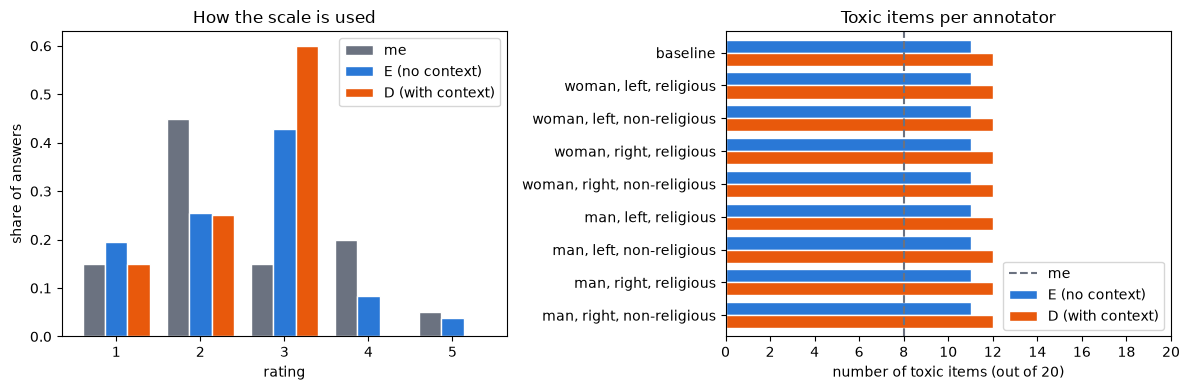

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"me": "#6b7280", "E (no context)": "#2a78d6", "D (with context)": "#e8590c"}

# share of each rating: me vs all the annotators of each condition together
shares = pd.DataFrame({
    "me": items_rated.rating.value_counts(normalize=True),
    "E (no context)": annotations_without_context.rating.value_counts(normalize=True),
    "D (with context)": annotations_with_context.rating.value_counts(normalize=True),
}).reindex(range(1, 6), fill_value=0)
shares.plot.bar(ax=axes[0], color=colors, width=0.8, edgecolor="white", rot=0)
axes[0].set(title="How the scale is used", xlabel="rating", ylabel="share of answers")

# toxic items per annotator in each condition, my number as a dashed line
toxic = pd.DataFrame({
    cond: (ann.label == "toxic").groupby(ann.annotator).sum()
    for cond, ann in [("E", annotations_without_context), ("D", annotations_with_context)]
}).reindex(list(ANNOTATORS))
toxic.plot.barh(ax=axes[1], color=[colors["E (no context)"], colors["D (with context)"]], width=0.8, edgecolor="white")
axes[1].axvline((items_rated.label == "toxic").sum(), color=colors["me"], linestyle="--", label="me")
axes[1].set(title="Toxic items per annotator", xlabel="number of toxic items (out of 20)", ylabel="", xlim=(0, 20), xticks=range(0, 21, 2))
axes[1].invert_yaxis()
axes[1].legend(["me", "E (no context)", "D (with context)"], loc="lower right")

plt.tight_layout()
plt.show()

The model uses the scale differently from me: I give mostly 2s and spread the toxic items over 3-5, while the
model piles up on 3 (60% of the answers in D) and rarely gives a 4 or a 5 (never in D). So every annotator calls more
items toxic than I do (11 in E, 12 in D, against my 8), and the bars of D are all the same length because the
9 annotators give identical ratings with context.

### How we measure agreement

Simple agreement: the share of the 20 items on which two annotators give the same answer, with the items matched
by id. We compute it twice: for the **label** (civil 1-2 vs toxic 3-5) and for the exact **rating** (1-5). All 360
answers have a valid rating, so all of them are kept: the invalid answers only have bad evidence, and the evidence
is not compared.

In [22]:
def wide(ann, column):
    """One row per item (sorted by id) and one column per annotator, in the order of ANNOTATORS."""
    return ann.pivot(index="id", columns="annotator", values=column)[list(ANNOTATORS)]


def pct(df):
    """Agreement shares as whole percentages."""
    return (df * 100).round().astype(int)


me = items_rated.set_index("id")                         # my ratings and labels, by id
ratings = {"E": wide(annotations_without_context, "rating").astype(int), "D": wide(annotations_with_context, "rating").astype(int)}
labels = {"E": wide(annotations_without_context, "label"), "D": wide(annotations_with_context, "label")}

### 1 and 2. Me against each annotator, without context (E) and with context (D)

For every annotator, the share of the 20 items on which it gives the same label and the same rating as me.

label     rating    
                                E   D      E   D
annotator                                       
baseline                       65  60     35  35
woman, left, religious         65  60     35  35
woman, left, non-religious     65  60     35  35
woman, right, religious        65  60     30  35
woman, right, non-religious    65  60     35  35
man, left, religious           65  60     30  35
man, left, non-religious       65  60     35  35
man, right, religious          65  60     40  35
man, right, non-religious      65  60     35  35

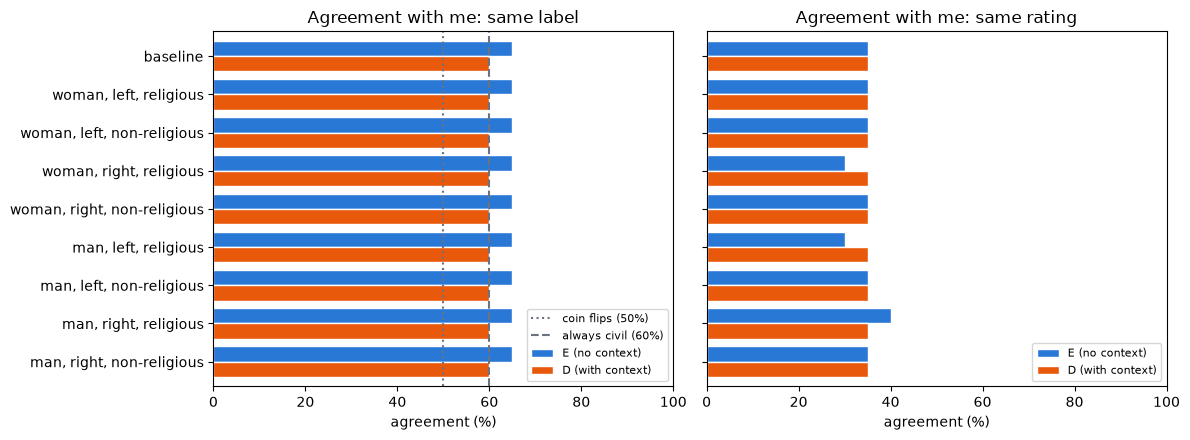

In [23]:
vs_me = pd.DataFrame({
    (measure, cond): table[cond].eq(me[measure], axis=0).mean()          # same answer as me, item by item
    for measure, table in [("label", labels), ("rating", ratings)]
    for cond in ["E", "D"]
})
display(pct(vs_me))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
colors = {"E": "#2a78d6", "D": "#e8590c"}
for ax, measure in zip(axes, ["label", "rating"]):
    (vs_me[measure] * 100).plot.barh(ax=ax, color=colors, width=0.8, edgecolor="white")
    ax.set(title=f"Agreement with me: same {measure}", xlabel="agreement (%)", xlim=(0, 100), ylabel="")
axes[0].axvline(50, color="#6b7280", linestyle=":", label="coin flips (50%)")
axes[0].axvline(60, color="#6b7280", linestyle="--", label="always civil (60%)")
axes[0].invert_yaxis()
axes[0].legend(["coin flips (50%)", "always civil (60%)", "E (no context)", "D (with context)"], loc="lower right", fontsize=8)
axes[1].legend(["E (no context)", "D (with context)"], loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**The ranking.** The personas ranked by agreement with me in each condition (label first, then rating), and the
closest one with all its attributes, next to the baseline.

In [24]:
for cond in ["E", "D"]:
    ranking = pct(vs_me.xs(cond, axis=1, level=1)).sort_values(["label", "rating"], ascending=False)
    personas = ranking.drop("baseline")
    closest = personas[(personas == personas.iloc[0]).all(axis=1)].index            # every persona tied at the top
    print(f"{cond}: closest persona(s):", "; ".join(" / ".join(ANNOTATORS[name].values()) for name in closest),
          f"with {personas.iloc[0].label}% label and {personas.iloc[0].rating}% rating agreement;",
          f"baseline: {ranking.loc['baseline', 'label']}% and {ranking.loc['baseline', 'rating']}%")
    display(ranking.rename(columns={"label": f"label ({cond})", "rating": f"rating ({cond})"}).T)

E: closest persona(s): man / right / religious with 65% label and 40% rating agreement; baseline: 65% and 35%


annotator,"man, right, religious",baseline,"woman, left, religious","woman, left, non-religious","woman, right, non-religious","man, left, non-religious","man, right, non-religious","woman, right, religious","man, left, religious"
label (E),65,65,65,65,65,65,65,65,65
rating (E),40,35,35,35,35,35,35,30,30


D: closest persona(s): woman / left / religious; woman / left / non-religious; woman / right / religious; woman / right / non-religious; man / left / religious; man / left / non-religious; man / right / religious; man / right / non-religious with 60% label and 35% rating agreement; baseline: 60% and 35%


annotator,baseline,"woman, left, religious","woman, left, non-religious","woman, right, religious","woman, right, non-religious","man, left, religious","man, left, non-religious","man, right, religious","man, right, non-religious"
label (D),60,60,60,60,60,60,60,60,60
rating (D),35,35,35,35,35,35,35,35,35


**Does a persona rate like me?** Not really, and no persona does better than the baseline.

- **Label.** Every annotator gives the same civil/toxic labels as every other in both D and E, so they all
  agree with me on the same share: **65% in E** and **60% in D**. That is only one item above, and then exactly
  equal to, an annotator that calls everything civil (60%). The labels the model gets wrong are mostly items I
  found civil and it calls toxic (it gives a borderline 3), plus items 17 and 18, which I rated toxic (3 and 4) and it calls civil.
- **Exact rating.** Agreement is low: **30-40% in E** and **35% for everyone in D**. The closest persona in E is
  **man / right / religious** (40%), but it is only one item (5 points) above the baseline (35%), which is within the
  noise of 20 items. Two personas (man / left / religious and woman / right / religious) are one item below it.
- **With context (D).** The conversation does not bring the model closer to me: the label agreement drops from 65%
  to 60% (one item), and the small differences between personas in E disappear, since in D all 9 annotators give
  identical ratings. With context, the closest persona is all of them at once, tied with the baseline.

### 3. Each annotator without context against with context (E vs D)

How much the conversation moves each annotator on its own: the share of items with the same answer in E and D.

In [25]:
e_vs_d = pd.DataFrame({measure: (table["E"] == table["D"]).mean() for measure, table in [("label", labels), ("rating", ratings)]})
display(pct(e_vs_d).T)

annotator,baseline,"woman, left, religious","woman, left, non-religious","woman, right, religious","woman, right, non-religious","man, left, religious","man, left, non-religious","man, right, religious","man, right, non-religious"
label,85,85,85,85,85,85,85,85,85
rating,75,65,65,65,70,65,65,75,70


**How much does the context move an annotator?** The labels change on 3 of the 20 items for every annotator (85%
the same): items 4 and 8 become toxic with the conversation and item 7 becomes civil. The exact rating moves more,
on 5-7 items (65-75% the same), mostly by pulling the 4s and 5s of E down to 3. The **baseline is moved the
least** (75%, together with man / right / religious), while the four left-wing personas and woman / right / religious
are moved the most (65%), because they are the ones that gave the 5s in E (items 6 and 10).

### 4. Persona against persona, within each condition

The agreement of every pair of annotators (the baseline is one more annotator), for the label and the rating, in
both conditions, and the average over all pairs.

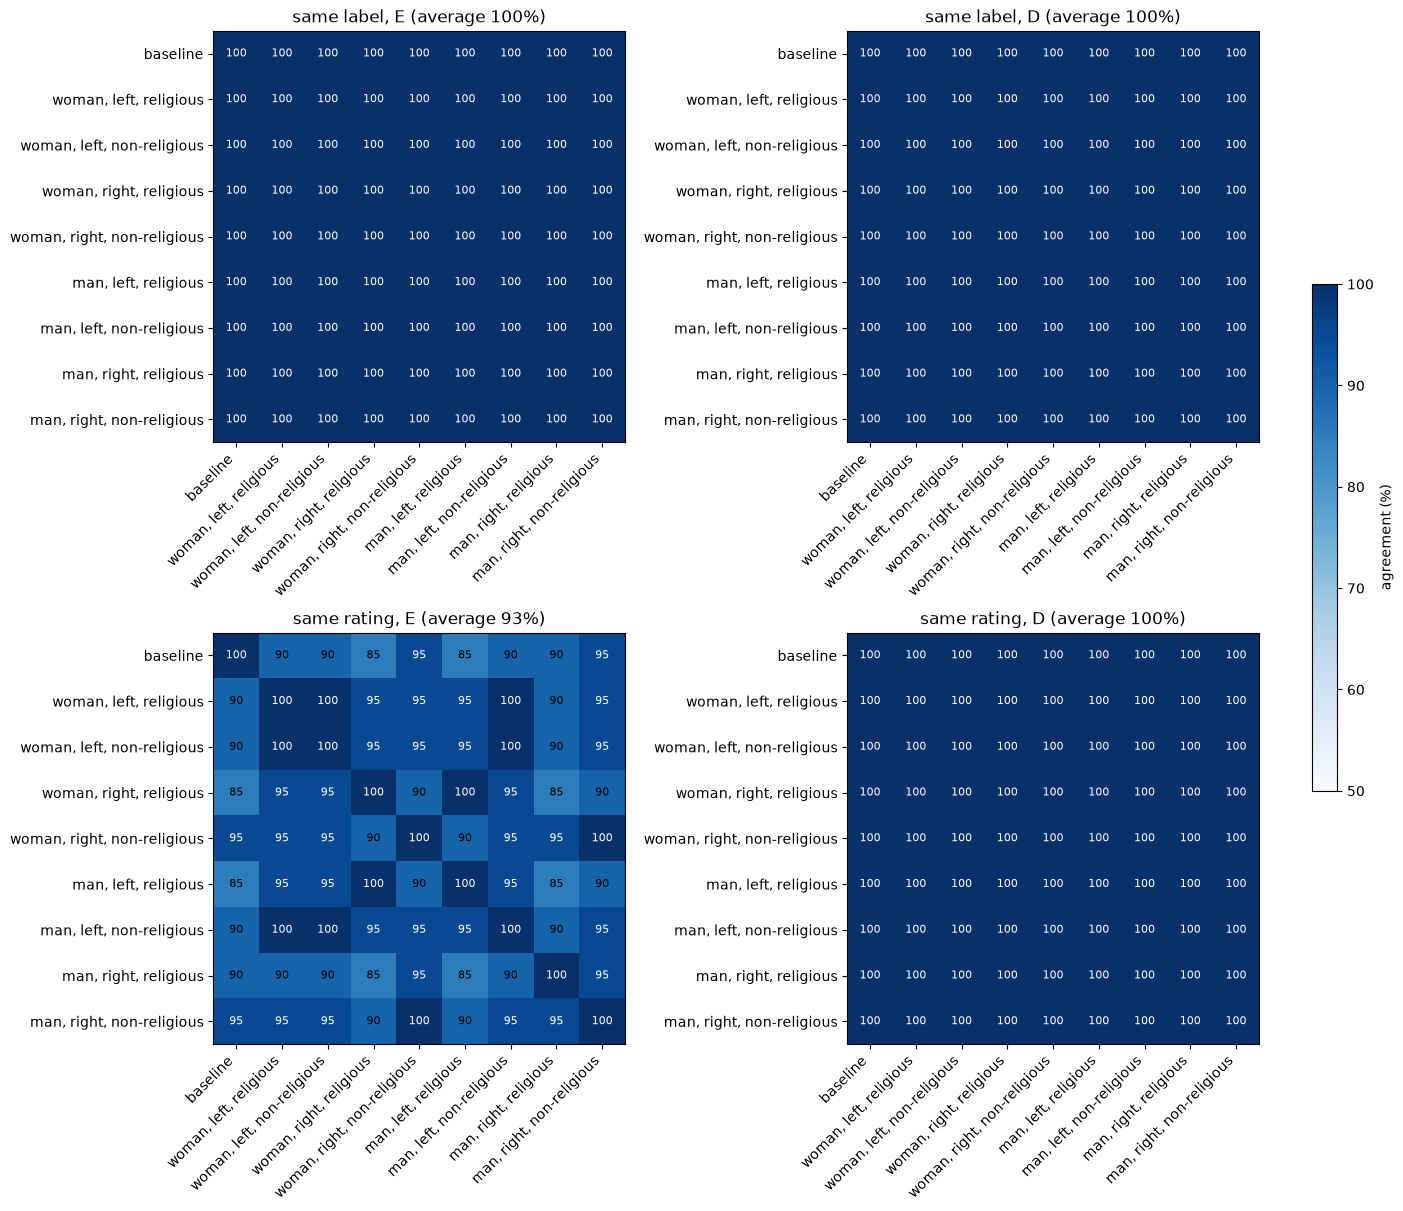

In [26]:
def pairwise(table):
    """Agreement of every pair of annotators (columns of the table)."""
    return pd.DataFrame({a: {b: (table[a] == table[b]).mean() for b in table} for a in table})[list(table)]


def average(matrix):
    """Average over all pairs (the upper triangle, without the diagonal)."""
    return matrix.values[np.triu_indices(len(matrix), 1)].mean()


fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for row, (measure, table) in enumerate([("label", labels), ("rating", ratings)]):
    for col, cond in enumerate(["E", "D"]):
        matrix = pct(pairwise(table[cond]))
        ax = axes[row, col]
        im = ax.imshow(matrix, cmap="Blues", vmin=50, vmax=100)
        for (i, j), v in np.ndenumerate(matrix.values):
            ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > 90 else "black")
        ax.set(title=f"same {measure}, {cond} (average {average(matrix):.0f}%)",
               xticks=range(len(matrix)), yticks=range(len(matrix)), yticklabels=matrix.index)
        ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
fig.colorbar(im, ax=axes, shrink=0.5, label="agreement (%)")
plt.show()

**Which dimension separates the personas the most?** For each dimension, the average rating agreement of the pairs
of personas that differ only in that dimension (4 pairs each, e.g. `woman, left, religious` vs
`man, left, religious` for gender). The lower it is, the more that dimension changes the ratings.

In [27]:
def pairs_differing_only_in(dimension):
    """The pairs of personas whose attributes differ only in this dimension."""
    personas = [name for name in ANNOTATORS if name != "baseline"]
    return [(a, b) for a, b in itertools.combinations(personas, 2)
            if [d for d in GRID if ANNOTATORS[a][d] != ANNOTATORS[b][d]] == [dimension]]


by_dimension = pd.DataFrame({
    cond: {dim: np.mean([(ratings[cond][a] == ratings[cond][b]).mean() for a, b in pairs_differing_only_in(dim)]) for dim in GRID}
    for cond in ["E", "D"]
})
display(pct(by_dimension).rename_axis("dimension"))

,E,D
dimension,,
gender,95,100
politics,92,100
religion,95,100


**Does identity matter?** Very little. The labels are the same for every pair in both conditions (100%), so the
persona never changes whether a comment is civil or toxic. The ratings differ a little only in E (93% on average):
every pair still agrees on at least 17 of the 20 items. **Politics** separates the personas the most (92%), ahead
of gender and religion (95% each), but this is a difference of about one item. The clearest example is item 10,
which the four left-wing personas rate 5 and three of the four right-wing ones rate 3. With the conversation the
personas agree completely (100% for every pair): the context removes the little effect the identity had.

### General conclusion

1. **Does a model that plays a person rate like a real person?** Not really. The model calls more comments toxic
   than I do, often giving a borderline 3 where I see a civil comment. The closest persona is
   **man / right / religious**, but only by a very small margin, so no persona is really closer to me than the
   baseline.
2. **Does reading the conversation bring the models closer to me?** No. With context they move slightly further
   away, and every annotator ends up rating exactly like the baseline.
3. **How much does the context move an annotator on its own?** A little: it flips the label of a few items and
   pulls the strongest ratings down to a borderline 3. The baseline is moved less than most personas, because the
   personas gave the extreme ratings that the context then softens.
4. **Does identity matter at all?** Very little. The personas never disagree on whether a comment is civil or
   toxic, only on the exact rating of a few items. Politics separates them the most, gender and religion less.
   Once they read the conversation, the differences vanish and they all agree.

**In short:** the identity the model plays matters far less than the model itself. The personas add small
differences that the conversation erases, and neither the personas nor the context bring the model closer to how
I judge toxicity.

---

> **AI disclaimer.** I used an LLM (Claude Code, Claude Opus 5.5) as an assistant while doing this assignment, for
> help with the code and the wording of the explanations. My own annotation (part A) was done by me alone, before
> seeing any model output, and all choices and conclusions are my own. See
> [`llm_interactions.md`](https://github.com/PetridhsG/practical-data-science-assignment-1/blob/main/llm_interactions.md)
> for the prompts and answers exchanged with the LLM.